# PCA

Optical recognition of handwritten digits dataset

In [ ]:
import pandas as pd
import numpy as np

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier

from sklearn.model_selection import train_test_split

from sklearn.decomposition import PCA

from sklearn.datasets import load_digits
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

In [ ]:
digit_data= load_digits()
print(dir(digit_data))
# print(digit_data.images)

['DESCR', 'data', 'feature_names', 'frame', 'images', 'target', 'target_names']


In [ ]:
df = pd.DataFrame(digit_data.data,columns=digit_data.feature_names)
df['Target'] = digit_data.target
df.head(5)
df.shape

(1797, 65)

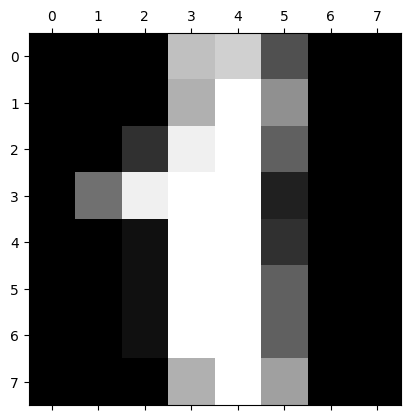

In [ ]:
plt.matshow(digit_data.images[1])
plt.gray()

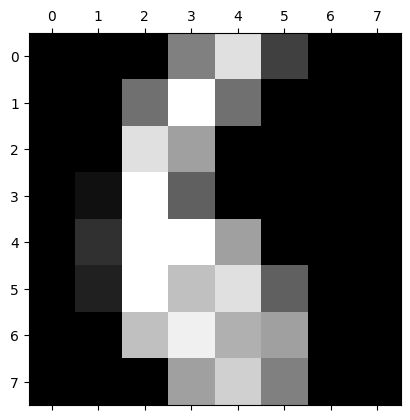

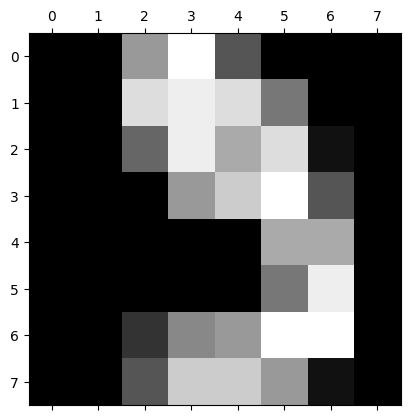

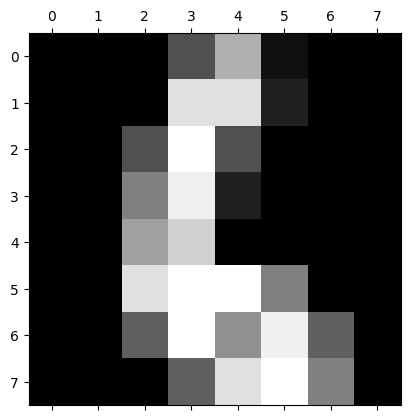

In [ ]:
for i in range(104,107):
#     print("*******",digit_data.target[i])
    plt.matshow(digit_data.images[i])
    plt.gray()
#     print(df.iloc[i])

In [ ]:
df

,pixel_0_0,pixel_0_1,pixel_0_2,pixel_0_3,pixel_0_4,pixel_0_5,pixel_0_6,pixel_0_7,pixel_1_0,pixel_1_1,...,pixel_6_7,pixel_7_0,pixel_7_1,pixel_7_2,pixel_7_3,pixel_7_4,pixel_7_5,pixel_7_6,pixel_7_7,Target
0,0.0,0.0,5.0,13.0,9.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,6.0,13.0,10.0,0.0,0.0,0.0,0
1,0.0,0.0,0.0,12.0,13.0,5.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,11.0,16.0,10.0,0.0,0.0,1
2,0.0,0.0,0.0,4.0,15.0,12.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,3.0,11.0,16.0,9.0,0.0,2
3,0.0,0.0,7.0,15.0,13.0,1.0,0.0,0.0,0.0,8.0,...,0.0,0.0,0.0,7.0,13.0,13.0,9.0,0.0,0.0,3
4,0.0,0.0,0.0,1.0,11.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,2.0,16.0,4.0,0.0,0.0,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1792,0.0,0.0,4.0,10.0,13.0,6.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,2.0,14.0,15.0,9.0,0.0,0.0,9
1793,0.0,0.0,6.0,16.0,13.0,11.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,6.0,16.0,14.0,6.0,0.0,0.0,0
1794,0.0,0.0,1.0,11.0,15.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,2.0,9.0,13.0,6.0,0.0,0.0,8
1795,0.0,0.0,2.0,10.0,7.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,5.0,12.0,16.0,12.0,0.0,0.0,9


### Train Test Split

In [ ]:
x = df.drop('Target',axis = 1)
y = df['Target']
x_train, x_test, y_train, y_test = train_test_split(x,y,test_size=0.25, random_state=21, stratify=y)

### Without PCA

In [ ]:
# Preprocessing
std_scaler = StandardScaler()
std_array = std_scaler.fit_transform(x_train)
x_train_std = pd.DataFrame(std_array,columns=x_train.columns)


In [ ]:
# Model Training
knn_model = KNeighborsClassifier()
knn_model.fit(x_train_std, y_train)
knn_model.score(x_train_std, y_train)

0.9799554565701559

### With PCA

In [ ]:
# x_train

In [ ]:
# Preprocessing
std_scaler = StandardScaler()
std_array = std_scaler.fit_transform(x_train)
x_train_std = pd.DataFrame(std_array,columns=x_train.columns)

pca = PCA(n_components=16)
x_train_pca = pca.fit_transform(x_train_std)
pc_names = [f'PC{i}' for i in range(1,x_train_pca.shape[1]+1)]
x_train_pca = pd.DataFrame(x_train_pca,columns=pc_names)

# Model Training
knn_model = KNeighborsClassifier()
knn_model.fit(x_train_pca, y_train)
knn_model.score(x_train_pca, y_train)

0.9784706755753526

In [ ]:
x_train_pca.shape

(1347, 16)

In [ ]:
x_train_pca

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,PC11,PC12,PC13,PC14,PC15,PC16
0,4.982826,2.552736,1.236920,-7.364557,0.436311,3.943463,0.134453,-2.978368,-0.642645,-3.417754,2.755087,-1.236184,0.760038,2.844513,0.555905,-0.304364
1,-2.304484,-1.934492,0.077750,-0.470116,-1.027396,-1.034997,0.372774,-0.586701,1.262951,0.712291,-0.665513,0.344213,1.722245,-0.301874,-0.700850,-1.283912
2,-1.527186,-1.846958,-5.435669,-3.176940,-0.360375,-0.117804,-1.271508,1.520988,-0.107583,0.251975,0.983907,-0.653904,-0.322784,0.221530,0.399262,-0.514847
3,2.279446,1.927931,-0.453144,-3.735862,-0.566125,3.825215,1.973288,-0.242679,0.820116,-3.096451,1.328484,1.113208,0.835093,0.290642,1.114423,1.388820
4,-3.863246,0.190537,0.571684,2.214690,-3.394029,2.490796,-0.398737,-1.788304,-2.673145,-1.564920,1.746727,-1.286546,-0.804488,-0.401822,0.134368,1.229914
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1342,0.810846,-1.192781,-1.906114,2.101745,0.025348,-0.000523,0.970579,-0.181422,-0.094727,0.274890,-2.625230,0.612360,0.434794,0.173872,-0.162198,0.486715
1343,-1.225226,0.705837,4.443864,-0.807997,-0.698002,-1.313893,0.499475,-0.521060,-0.080685,1.371341,-1.904662,0.683015,-0.836462,0.915802,0.250249,1.402358
1344,-2.310984,3.810163,-0.420773,0.291219,-0.442923,-1.782690,-2.109612,0.506485,-0.535401,-1.112918,1.419795,-0.045348,1.292205,-0.741022,-0.225498,-1.538379
1345,-4.276435,-2.963717,-0.167374,-0.830917,-2.137228,3.278546,-0.470147,0.523907,0.802357,-1.473441,1.135167,-1.230372,0.482951,0.667656,0.666353,1.255869


In [ ]:
std_scaler = StandardScaler()
std_array = std_scaler.fit_transform(x_train)
x_train_std = pd.DataFrame(std_array,columns=x_train.columns)

accuracy_list = []
for i in range(1,x_train_std.shape[1]+1):

    pca = PCA(n_components=i)
    x_train_pca = pca.fit_transform(x_train_std)
    pc_names = [f'PC{i}' for i in range(1,x_train_pca.shape[1]+1)]
    x_train_pca = pd.DataFrame(x_train_pca,columns=pc_names)

    # Model Training
    knn_model = KNeighborsClassifier()
    knn_model.fit(x_train_pca, y_train)
    accuracy_list.append(knn_model.score(x_train_pca, y_train))
accuracy_list[15]

0.9784706755753526

Text(0.5, 0, 'PC Values')

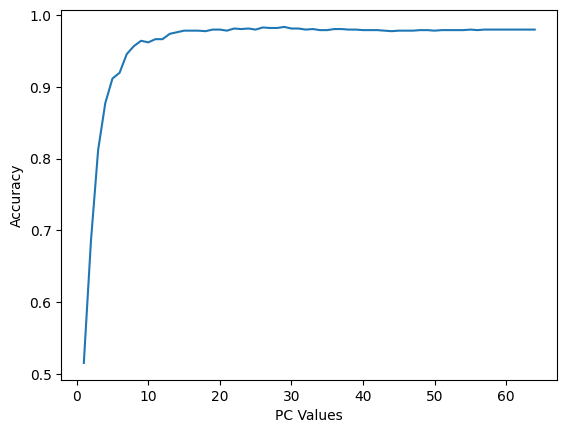

In [ ]:
plt.plot(range(1,65),accuracy_list)
plt.ylabel('Accuracy')
plt.xlabel("PC Values")